In [1]:
# Copyright (c) Microsoft Corporation.
# Licensed under the MIT License.

"""Benchmark all the baseline agents
on a given CyberBattleSim environment and compare
them to the dumb 'random agent' baseline.

NOTE: You can run this `.py`-notebook directly from VSCode.
You can also generate a traditional Jupyter Notebook
using the VSCode command `Export Currenty Python File As Jupyter Notebook`.
"""

# pylint: disable=invalid-name

"Benchmark all the baseline agents\non a given CyberBattleSim environment and compare\nthem to the dumb 'random agent' baseline.\n\nNOTE: You can run this `.py`-notebook directly from VSCode.\nYou can also generate a traditional Jupyter Notebook\nusing the VSCode command `Export Currenty Python File As Jupyter Notebook`.\n"

In [2]:
import sys
import os
import logging
import gymnasium as gym
import cyberbattle.agents.baseline.learner as learner
import cyberbattle.agents.baseline.plotting as p
import cyberbattle.agents.baseline.agent_wrapper as w
import cyberbattle.agents.baseline.agent_dql as dqla
from cyberbattle.agents.baseline.agent_wrapper import Verbosity
from cyberbattle._env.cyberbattle_env import CyberBattleEnv

logging.basicConfig(stream=sys.stdout, level=logging.ERROR, format="%(levelname)s: %(message)s")

In [3]:
%matplotlib inline

In [4]:
env_configs = [
    {
        "gym_id": "CyberBattleToyCtf-v0",
        "title": "DQL"
    },
    {
        "gym_id": "CyberBattleToyCtf-v0-2HoneyTokens",
        "title": "DQL with 2 Honeytokens"
    },
    {
        "gym_id": "CyberBattleToyCtf-v0-4HoneyTokens",
        "title": "DQL with 4 Honeytokens"
    },
    {
        "gym_id": "CyberBattleToyCtf-v0-6HoneyTokens",
        "title": "DQL with 6 Honeytokens"
    },
]

In [ ]:
# Parameters
env_size = None
iteration_count = 1500
training_episode_count = 10
eval_episode_count = 10
maximum_node_count = 12
maximum_total_credentials = 10
plots_dir = "notebooks/output/benchmark/plots"


In [6]:
os.makedirs(plots_dir, exist_ok=True)
from typing import cast

all_runs = [];

In [7]:
for env_config in env_configs:
    print(f"Running benchmark for {env_config['gym_id']}...")
    # Load the Gym environment
    if env_size:
        _gym_env = gym.make(env_config['gym_id'], size=env_size)
    else:
        _gym_env = gym.make(env_config['gym_id'])

    gym_env = cast(CyberBattleEnv, _gym_env.unwrapped)

    print(f"Gym environment: {gym_env}")

    assert isinstance(gym_env, CyberBattleEnv), f"Expected CyberBattleEnv, got {type(gym_env)}"

    ep = w.EnvironmentBounds.of_identifiers(maximum_node_count=maximum_node_count, maximum_total_credentials=maximum_total_credentials, identifiers=gym_env.identifiers)

    debugging = False
    if debugging:
        print(f"port_count = {ep.port_count}, property_count = {ep.property_count}")

        gym_env.environment
        # training_env.environment.plot_environment_graph()
        gym_env.environment.network.nodes
        gym_env.action_space
        gym_env.action_space.sample()
        gym_env.observation_space.sample()
        o0, _ = gym_env.reset()
        o_test, r, d, t, i = gym_env.step(gym_env.sample_valid_action())
        o0, _ = gym_env.reset()

        o0.keys()

        fe_example = w.RavelEncoding(ep, [w.Feature_active_node_properties(ep), w.Feature_discovered_node_count(ep)])
        a = w.StateAugmentation(o0)
        w.Feature_discovered_ports(ep).get(a)
        fe_example.encode_at(a, 0)

    # Evaluate the Deep Q-learning agent
    dql_run = learner.epsilon_greedy_search(
        cyberbattle_gym_env=gym_env,
        environment_properties=ep,
        learner=dqla.DeepQLearnerPolicy(
            ep=ep,
            gamma=0.015,
            replay_memory_size=10000,
            target_update=10,
            batch_size=512,
            # torch default learning rate is 1e-2
            # a large value helps converge in less episodes
            learning_rate=0.01,
        ),
        episode_count=training_episode_count,
        iteration_count=iteration_count,
        epsilon=0.90,
        epsilon_exponential_decay=5000,
        epsilon_minimum=0.10,
        verbosity=Verbosity.Quiet,
        render=False,
        plot_episodes_length=False,
        title=env_config['title'],
    )

    all_runs.append(dql_run)

Running benchmark for CyberBattleToyCtf-v0...
Gym environment: <CyberBattleToyCtf<CyberBattleToyCtf-v0>>
###### DQL
Learning with: episode_count=10,iteration_count=1500,ϵ=0.9,ϵ_min=0.1, ϵ_expdecay=5000,γ=0.015, lr=0.01, replaymemory=10000,
batch=512, target_update=10
  ## Episode: 1/10 'DQL' ϵ=0.9000, γ=0.015, lr=0.01, replaymemory=10000,
batch=512, target_update=10


Episode 1|Iteration 0|reward: ------|last_reward_at: ----|Elapsed Time: 0:00:00||
Episode 1|Iteration 1|reward:    0.0|last_reward_at: ----|Elapsed Time: 0:00:00||
Episode 1|Iteration 2|reward:   11.0|last_reward_at: ----|Elapsed Time: 0:00:00||
Episode 1|Iteration 2|reward:   11.0|last_reward_at:    2|Elapsed Time: 0:00:00||
/Users/phurwasherpa/Downloads/CyberBattleSim/cyberbattle/agents/baseline/agent_dql.py:408: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:278.)
  state_batch = torch.tensor(states_to_consider).to(device)
Episode 1|Iteration 8|reward:   22.0|last_reward_at:    2|Elapsed Time: 0:00:00||
Episode 1|Iteration 8|reward:   22.0|last_reward_at:    8|Elapsed Time: 0:00:00||
Episode 1|Iteration 19|reward:   22.0|last_reward_at:    8|

  Episode 1 stopped at t=1500 
  Breakdown [Reward/NoReward (Success rate)]
    explore-local: 3/116 (0.03)
    explore-remote: 8/582 (0.01)
    explore-connect: 4/537 (0.01)
    exploit-local: 0/28 (0.00)
    exploit-remote: 0/171 (0.00)
    exploit-connect: 1/50 (0.02)
  exploit deflected to exploration: 61
  ## Episode: 2/10 'DQL' ϵ=0.6928, γ=0.015, lr=0.01, replaymemory=10000,
batch=512, target_update=10


Episode 2|Iteration 0|reward: ------|last_reward_at: ----|Elapsed Time: 0:00:00||
Episode 2|Iteration 1|reward:    0.0|last_reward_at: ----|Elapsed Time: 0:00:00||
Episode 2|Iteration 3|reward:   11.0|last_reward_at: ----|Elapsed Time: 0:00:00||
Episode 2|Iteration 3|reward:   11.0|last_reward_at:    3|Elapsed Time: 0:00:00||
Episode 2|Iteration 6|reward:   22.0|last_reward_at:    3|Elapsed Time: 0:00:00||
Episode 2|Iteration 6|reward:   22.0|last_reward_at:    6|Elapsed Time: 0:00:00||
Episode 2|Iteration 9|reward:   22.0|last_reward_at:    6|Elapsed Time: 0:00:00||
Episode 2|Iteration 13|reward:   22.0|last_reward_at:    6|Elapsed Time: 0:00:00||
Episode 2|Iteration 16|reward:   22.0|last_reward_at:    6|Elapsed Time: 0:00:00||
Episode 2|Iteration 19|reward:   22.0|last_reward_at:    6|Elapsed Time: 0:00:00||
Episode 2|Iteration 21|reward:   22.0|last_reward_at:    6|Elapsed Time: 0:00:00||
Episode 2|Iteration 26|reward:   22.0|last_reward_at:    6|Elapsed Time: 0:00:00||
Episode 2|I

  Episode 2 stopped at t=1500 
  Breakdown [Reward/NoReward (Success rate)]
    explore-local: 3/108 (0.03)
    explore-remote: 7/438 (0.02)
    explore-connect: 1/427 (0.00)
    exploit-local: 0/64 (0.00)
    exploit-remote: 1/411 (0.00)
    exploit-connect: 4/36 (0.10)
  exploit deflected to exploration: 68
  ## Episode: 3/10 'DQL' ϵ=0.5391, γ=0.015, lr=0.01, replaymemory=10000,
batch=512, target_update=10


...

  Episode 8 stopped at t=1500 
  Breakdown [Reward/NoReward (Success rate)]
    explore-local: 1/22 (0.04)
    explore-remote: 3/154 (0.02)
    explore-connect: 0/150 (0.00)
    exploit-local: 0/42 (0.00)
    exploit-remote: 12/972 (0.01)
    exploit-connect: 2/142 (0.01)
  exploit deflected to exploration: 45
  ## Episode: 9/10 'DQL with 6 Honeytokens' ϵ=0.1726, γ=0.015, lr=0.01, replaymemory=10000,
batch=512, target_update=10


Episode 9|Iteration 0|reward: ------|last_reward_at: ----|Elapsed Time: 0:00:00||
Episode 9|Iteration 1|reward:    0.0|last_reward_at: ----|Elapsed Time: 0:00:00||
Episode 9|Iteration 3|reward:   11.0|last_reward_at: ----|Elapsed Time: 0:00:00||
Episode 9|Iteration 3|reward:   11.0|last_reward_at:    3|Elapsed Time: 0:00:00||
Episode 9|Iteration 8|reward:   11.0|last_reward_at:    3|Elapsed Time: 0:00:00||
Episode 9|Iteration 13|reward:   22.0|last_reward_at:    3|Elapsed Time: 0:00:00||
Episode 9|Iteration 13|reward:   22.0|last_reward_at:   13|Elapsed Time: 0:00:00||
Episode 9|Iteration 18|reward:   31.0|last_reward_at:   13|Elapsed Time: 0:00:00||
Episode 9|Iteration 18|reward:   31.0|last_reward_at:   18|Elapsed Time: 0:00:00||
Episode 9|Iteration 23|reward:   37.0|last_reward_at:   18|Elapsed Time: 0:00:00||
Episode 9|Iteration 23|reward:   37.0|last_reward_at:   23|Elapsed Time: 0:00:00||
Episode 9|Iteration 27|reward:   46.0|last_reward_at:   23|Elapsed Time: 0:00:00||
Episode 9

  Episode 9 stopped at t=1500 
  Breakdown [Reward/NoReward (Success rate)]
    explore-local: 2/15 (0.12)
    explore-remote: 4/114 (0.03)
    explore-connect: 0/102 (0.00)
    exploit-local: 1/73 (0.01)
    exploit-remote: 11/957 (0.01)
    exploit-connect: 5/216 (0.02)
  exploit deflected to exploration: 5
  ## Episode: 10/10 'DQL with 6 Honeytokens' ϵ=0.1538, γ=0.015, lr=0.01, replaymemory=10000,
batch=512, target_update=10


Episode 10|Iteration 0|reward: ------|last_reward_at: ----|Elapsed Time: 0:00:00||
Episode 10|Iteration 1|reward:   11.0|last_reward_at: ----|Elapsed Time: 0:00:00||
Episode 10|Iteration 1|reward:   11.0|last_reward_at:    1|Elapsed Time: 0:00:00||
Episode 10|Iteration 6|reward:   11.0|last_reward_at:    1|Elapsed Time: 0:00:00||
Episode 10|Iteration 8|reward:   20.0|last_reward_at:    1|Elapsed Time: 0:00:00||
Episode 10|Iteration 8|reward:   20.0|last_reward_at:    8|Elapsed Time: 0:00:00||
Episode 10|Iteration 13|reward:   20.0|last_reward_at:    8|Elapsed Time: 0:00:00||
Episode 10|Iteration 19|reward:   20.0|last_reward_at:    8|Elapsed Time: 0:00:00||
Episode 10|Iteration 21|reward:   20.0|last_reward_at:    8|Elapsed Time: 0:00:00||
Episode 10|Iteration 26|reward:   20.0|last_reward_at:    8|Elapsed Time: 0:00:00||
Episode 10|Iteration 27|reward:   20.0|last_reward_at:    8|Elapsed Time: 0:00:00||
Episode 10|Iteration 31|reward:   34.0|last_reward_at:    8|Elapsed Time: 0:00:00|

  Episode 10 stopped at t=1500 
  Breakdown [Reward/NoReward (Success rate)]
    explore-local: 1/22 (0.04)
    explore-remote: 1/111 (0.01)
    explore-connect: 0/122 (0.00)
    exploit-local: 0/29 (0.00)
    exploit-remote: 14/1038 (0.01)
    exploit-connect: 2/160 (0.01)
  exploit deflected to exploration: 39
simulation ended


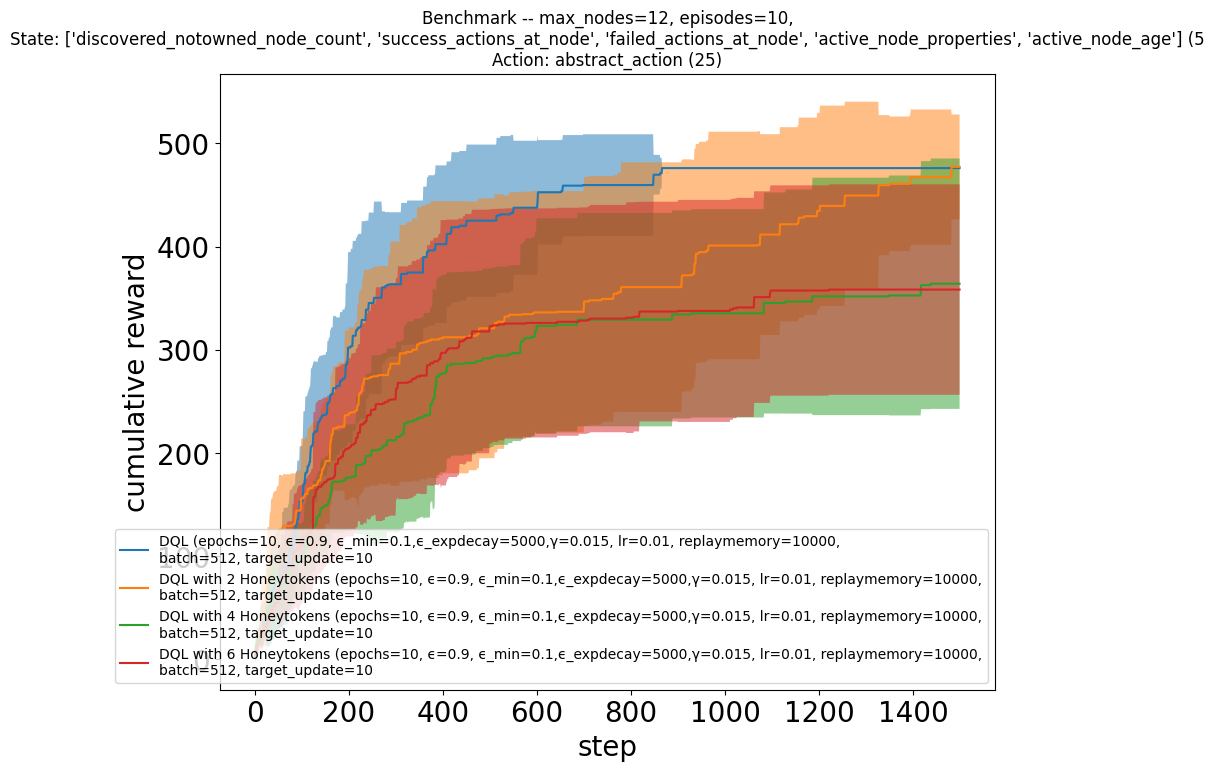

In [ ]:
themodel = dqla.CyberBattleStateActionModel(ep)
p.plot_averaged_cummulative_rewards(
    all_runs=all_runs,
    title=f"Benchmark -- max_nodes={ep.maximum_node_count}, episodes={eval_episode_count},\n"
    f"State: {[f.name() for f in themodel.state_space.feature_selection]} "
    f"({len(themodel.state_space.feature_selection)}\n"
    f"Action: abstract_action ({themodel.action_space.flat_size()})",
    save_at=os.path.join(plots_dir, f"benchmark-toy-honeytokens-cumrewards.png"),
)

In [9]:
# Plot cumulative rewards for all episodes
# for r in contenders:
#     p.plot_all_episodes(r)

Baseline vs 2 HoneyToken

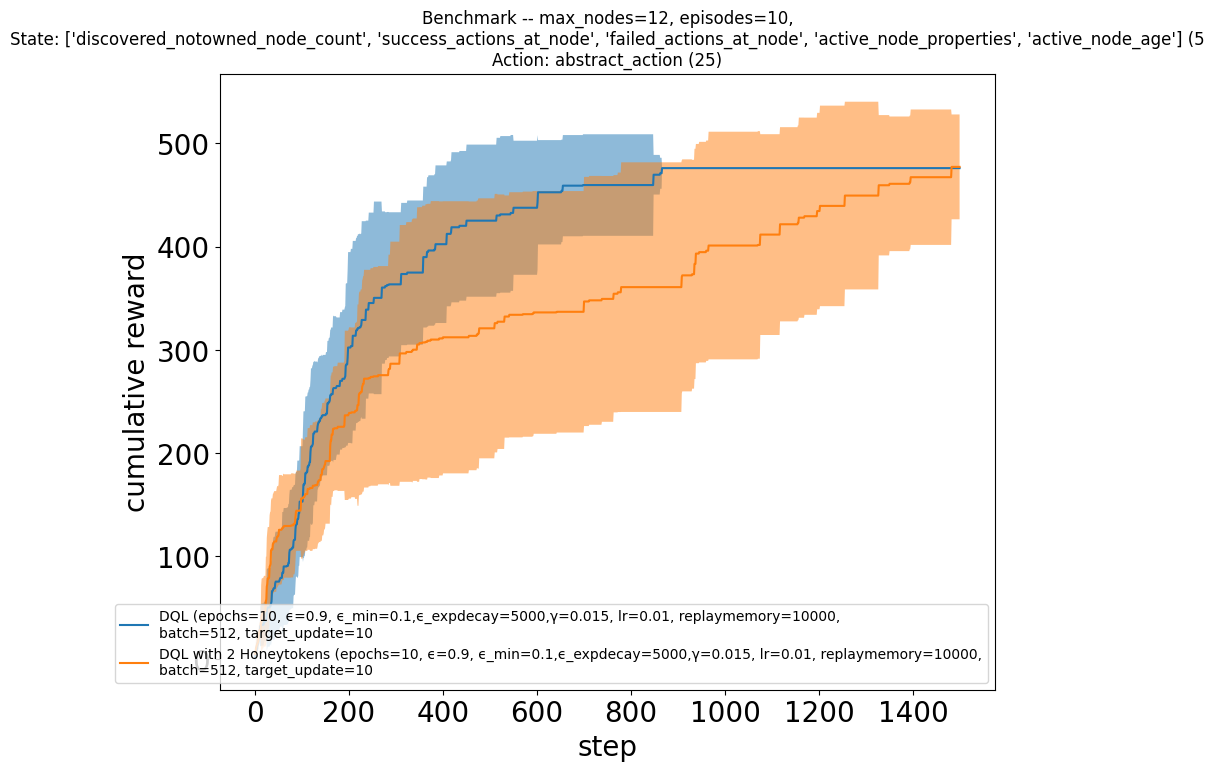

In [15]:
themodel = dqla.CyberBattleStateActionModel(ep)
p.plot_averaged_cummulative_rewards(
    all_runs=all_runs[:2],
    title=f"Benchmark -- max_nodes={ep.maximum_node_count}, episodes={eval_episode_count},\n"
    f"State: {[f.name() for f in themodel.state_space.feature_selection]} "
    f"({len(themodel.state_space.feature_selection)}\n"
    f"Action: abstract_action ({themodel.action_space.flat_size()})",
    save_at=os.path.join(plots_dir, f"benchmark-toyctf-baselinevs2honeytokens-cumrewards.png"),
)

Baseline vs 4 HoneyToken

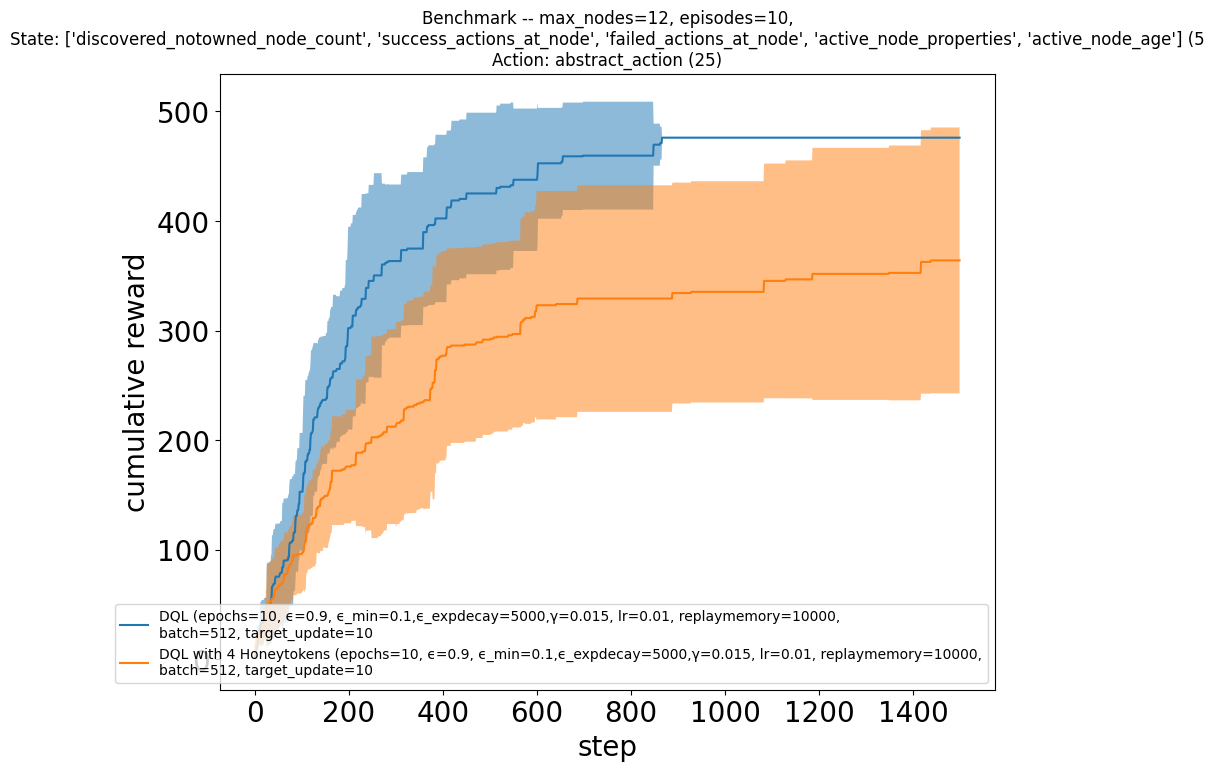

In [17]:
themodel = dqla.CyberBattleStateActionModel(ep)
p.plot_averaged_cummulative_rewards(
    all_runs=[all_runs[0], all_runs[2]],
    title=f"Benchmark -- max_nodes={ep.maximum_node_count}, episodes={eval_episode_count},\n"
    f"State: {[f.name() for f in themodel.state_space.feature_selection]} "
    f"({len(themodel.state_space.feature_selection)}\n"
    f"Action: abstract_action ({themodel.action_space.flat_size()})",
    save_at=os.path.join(plots_dir, f"benchmark-toyctf-baselinevs4honeytokens-cumrewards.png"),
)

Baseline vs 6 HoneyTokens

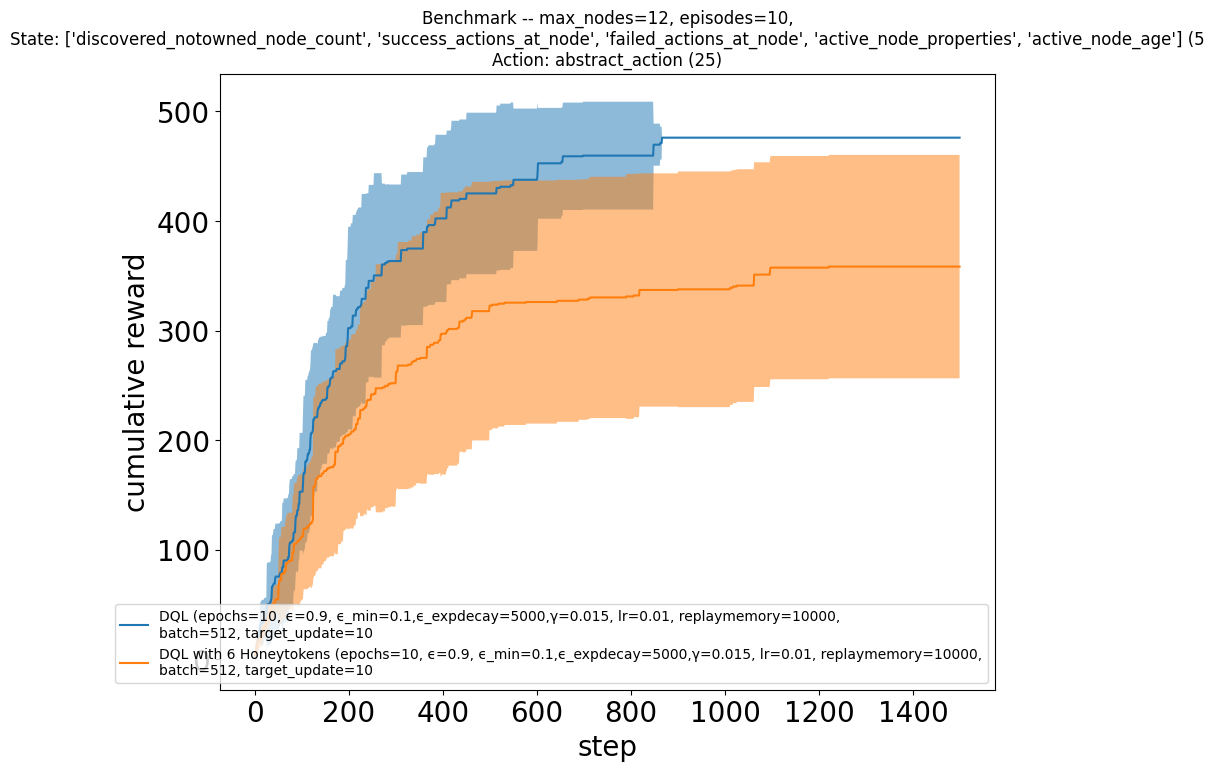

In [18]:
themodel = dqla.CyberBattleStateActionModel(ep)
p.plot_averaged_cummulative_rewards(
    all_runs=[all_runs[0], all_runs[3]],
    title=f"Benchmark -- max_nodes={ep.maximum_node_count}, episodes={eval_episode_count},\n"
    f"State: {[f.name() for f in themodel.state_space.feature_selection]} "
    f"({len(themodel.state_space.feature_selection)}\n"
    f"Action: abstract_action ({themodel.action_space.flat_size()})",
    save_at=os.path.join(plots_dir, f"benchmark-toyctf-baselinevs6honeytokens-cumrewards.png"),
)